In [14]:
!pip install koreanize-matplotlib
import koreanize_matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 32.4 MB/s eta 0:00:00


In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan

---
## STEP 1. EDA — 데이터 구조와 분포 탐색

### 해야 할 일
1. df.shape, df.info(), df.dtypes로 변수 타입과 행/열 수 확인
2. df.describe()로 수치형 변수의 요약 통계량 출력
3. df.isnull().sum()으로 결측치 개수 확인 — 어느 변수에 몇 개?
4. 수치형 변수의 히스토그램(또는 박스플롯)을 그려 분포 모양 관찰
5. 범주형 변수의 빈도표(value_counts) 확인

In [2]:
# 1-1) 데이터 불러오기 + 기본 구조
df = pd.read_csv('student_performance.csv')
print(f'shape: {df.shape}')
df.head()

shape: (200, 13)


,student_id,gender,major,year,prev_gpa,study_hours,sleep_hours,absences,commute_min,part_time_job,study_group,scholarship,final_score
0,ST0001,M,computer_science,1,2.88,4.3,7.0,1,5.0,no,yes,none,63.3
1,ST0002,F,data_science,4,3.01,3.4,7.8,2,115.0,no,yes,none,59.3
2,ST0003,F,data_science,3,3.19,6.1,7.1,6,45.0,no,yes,none,58.4
3,ST0004,F,computer_science,4,3.42,2.6,5.3,7,13.0,no,yes,full,57.8
4,ST0005,M,computer_science,2,3.20,22.8,7.4,1,62.0,yes,yes,full,78.0


In [3]:
# 1-1 변수 타입 정보
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   student_id     200 non-null    object 
 1   gender         200 non-null    object 
 2   major          200 non-null    object 
 3   year           200 non-null    int64  
 4   prev_gpa       200 non-null    float64
 5   study_hours    200 non-null    float64
 6   sleep_hours    188 non-null    float64
 7   absences       200 non-null    int64  
 8   commute_min    192 non-null    float64
 9   part_time_job  200 non-null    object 
 10  study_group    200 non-null    object 
 11  scholarship    200 non-null    object 
 12  final_score    200 non-null    float64
dtypes: float64(5), int64(2), object(6)
memory usage: 20.4+ KB


In [4]:
# 1-2) 수치형 요약
df.describe()

,year,prev_gpa,study_hours,sleep_hours,absences,commute_min,final_score
count,200.000000,200.00000,200.000000,188.000000,200.000000,192.000000,200.000000
mean,2.665000,3.19210,8.137000,6.762766,3.565000,32.036458,64.413500
std,1.135439,0.39671,7.781974,1.036188,1.866331,30.730099,8.335935
min,1.000000,1.99000,0.500000,3.000000,0.000000,5.000000,37.300000
25%,2.000000,2.95750,3.775000,6.000000,2.000000,10.750000,58.950000
50%,3.000000,3.19000,6.350000,6.800000,3.000000,23.000000,64.650000
75%,4.000000,3.45000,10.300000,7.400000,5.000000,41.000000,69.925000
max,4.000000,4.30000,58.800000,9.500000,9.000000,180.000000,90.600000


In [6]:
# 1-3) 결측치 위치
missing = df.isnull().sum()
print(missing[missing > 0])

sleep_hours    12
commute_min     8
dtype: int64


/tmp/ipykernel_1622/1316755702.py:6: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1622/1316755702.py:6: UserWarning: Glyph 52824 (\N{HANGUL SYLLABLE CI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1622/1316755702.py:6: UserWarning: Glyph 54805 (\N{HANGUL SYLLABLE HYEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1622/1316755702.py:6: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1622/1316755702.py:6: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1622/1316755702.py:6: UserWarning: Glyph 54252 (\N{HANGUL SYLLABLE PO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(

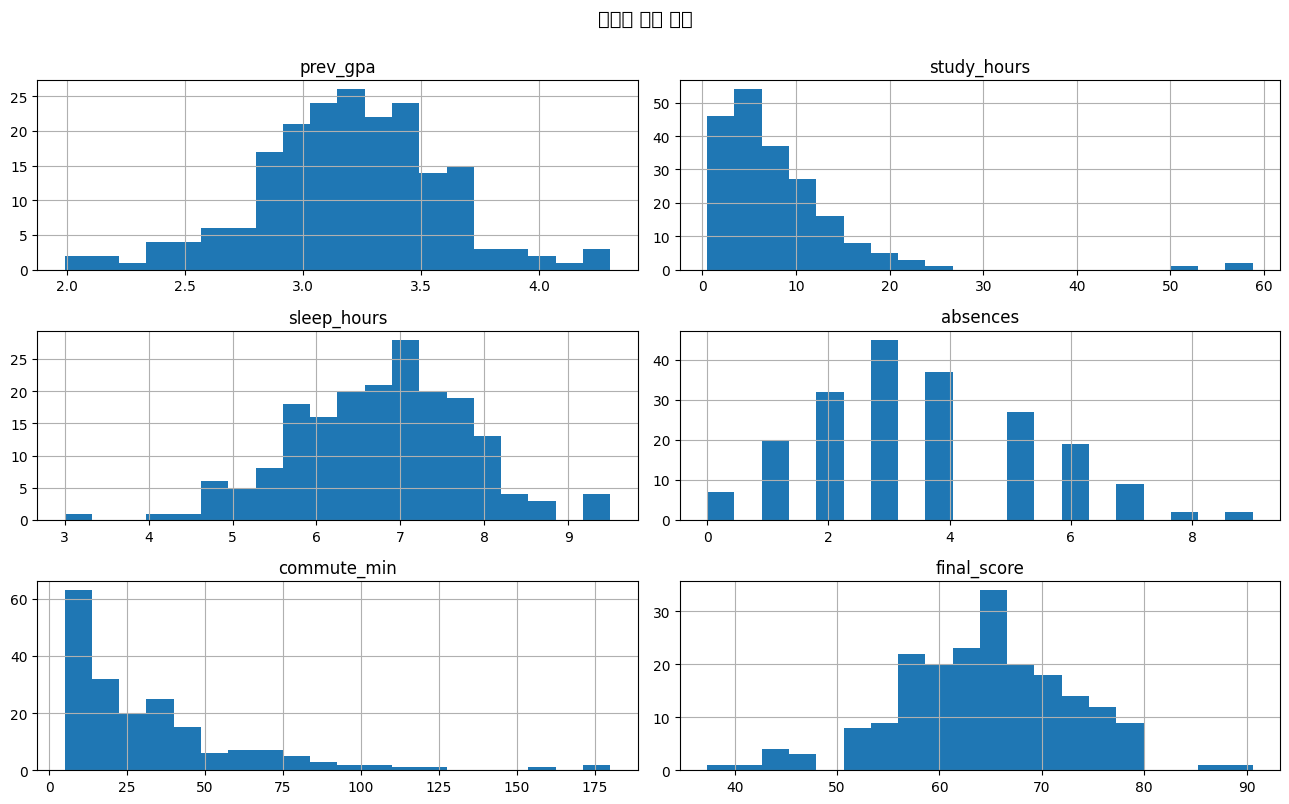

In [8]:
# 1-4) 수치형 히스토그램
num_cols = ['prev_gpa', 'study_hours', 'sleep_hours',
            'absences', 'commute_min', 'final_score']
df[num_cols].hist(figsize=(13, 8), bins=20)
plt.suptitle('수치형 변수 분포', fontsize=14, y=1.0)
plt.tight_layout()
plt.show()

In [13]:
# 1-4) 왜도(skewness)
print('수치형 변수의 왜도:')
for c in num_cols:
    print(f'  {c:20s}: skew = {df[c].skew():+.3f}')

수치형 변수의 왜도:
  prev_gpa            : skew = -0.171
  study_hours         : skew = +3.753
  sleep_hours         : skew = -0.192
  absences            : skew = +0.337
  commute_min         : skew = +2.054
  final_score         : skew = -0.236


In [12]:
# 1-5) 범주형 빈도표
cat_cols = ['gender', 'major', 'year', 'part_time_job', 'study_group', 'scholarship']
for c in cat_cols:
    print(f'\n[{c}]')
    print(df[c].value_counts())


[gender]
gender
M    108
F     92
Name: count, dtype: int64

[major]
major
computer_science    68
data_science        65
statistics          48
math                19
Name: count, dtype: int64

[year]
year
4    61
3    56
1    45
2    38
Name: count, dtype: int64

[part_time_job]
part_time_job
no     116
yes     84
Name: count, dtype: int64

[study_group]
study_group
yes    111
no      89
Name: count, dtype: int64

[scholarship]
scholarship
none       106
partial     64
full        30
Name: count, dtype: int64


### ✓ STEP 1 결과 해석

**기본 구조**
- 행 200, 열 13개. 학생 ID + 인구통계 4 + 학업/생활 5 + 환경 3 + Y(final_score) 1.

**결측치**
- `sleep_hours`: **12개**
- `commute_min`: **8개**
- 약 6~10% 수준 → STEP 2에서 처리

**분포 모양**
- 정규에 가까움: `prev_gpa`, `sleep_hours`, `final_score`
- 강하게 우편향: `study_hours` (skew **+3.75**), `commute_min` (+2.05)
- 약간 우편향: `absences` (+0.34)

→ `study_hours`와 `commute_min`은 STEP 3에서 **로그 변환** 필요.

**범주형 분포**
- `major`: computer_science(68) > data_science(65) > statistics(48) > math(19)
- `scholarship`: none(106) > partial(64) > full(30) — 장학금 없는 학생 절반 이상

---
## STEP 2. 결측치·이상치 처리

### 해야 할 일
1. 결측치 처리 — `dropna()` vs `fillna()`
2. `study_hours` 이상치 식별 (IQR)
3. 처리 결정과 근거
4. 처리 후 결과 확인

In [9]:
# 2-1) dropna 선택 (이유: 결측 비율 작고 무작위로 보임)
print(f'처리 전 행 수: {len(df)}')
df_clean = df.dropna().copy()
print(f'dropna 후 행 수: {len(df_clean)}')
print(f'제거된 행: {len(df) - len(df_clean)}개')
print(f'결측 잔여: {df_clean.isnull().sum().sum()}')

처리 전 행 수: 200
dropna 후 행 수: 180
제거된 행: 20개
결측 잔여: 0


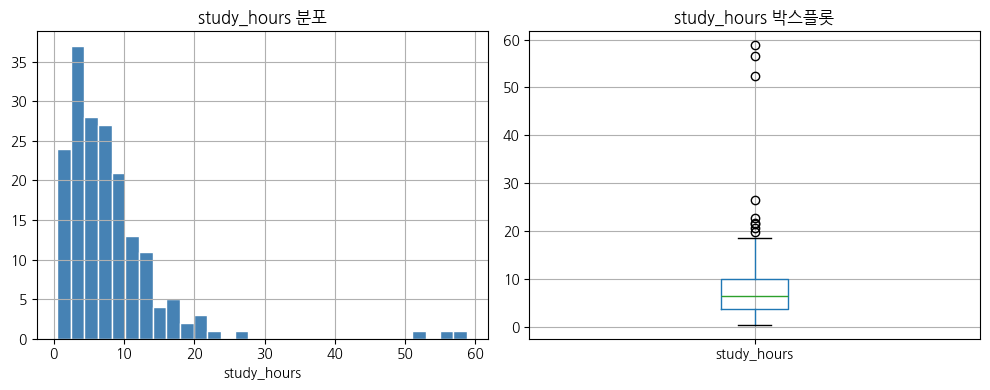

Q1=3.80, Q3=10.10, IQR=6.30
상한 (Q3 + 1.5·IQR) = 19.55

상한 초과 이상치 개수: 9
    student_id  study_hours  final_score
4       ST0005         22.8         78.0
74      ST0075         26.6         67.5
86      ST0087         21.8         78.2
110     ST0111         21.5         60.8
112     ST0113         56.6         44.9
113     ST0114         58.8         64.7
144     ST0145         19.8         67.1
168     ST0169         52.5         70.6
176     ST0177         20.6         65.7


In [35]:
# 2-2) study_hours 이상치 확인
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
df_clean['study_hours'].hist(bins=30, color='steelblue', edgecolor='white')
plt.xlabel('study_hours')
plt.title('study_hours 분포')
plt.subplot(1, 2, 2)
df_clean.boxplot(column='study_hours')
plt.title('study_hours 박스플롯')
plt.tight_layout()
plt.show()

Q1, Q3 = df_clean['study_hours'].quantile([0.25, 0.75])
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
print(f'Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}')
print(f'상한 (Q3 + 1.5·IQR) = {upper:.2f}')
outliers = df_clean[df_clean['study_hours'] > upper]
print(f'\n상한 초과 이상치 개수: {len(outliers)}')
print(outliers[['student_id', 'study_hours', 'final_score']])

In [11]:
# 2-3) 이상치는 보존 선택 (이유: 로그 변환으로 영향력 완화 예정)
print('처리 결정:')
print(' - 결측치: dropna')
print(' - 이상치: 보존 (STEP 3 로그 변환으로 완화)')
print(f'최종 분석 데이터: {df_clean.shape}')

처리 결정:
 - 결측치: dropna
 - 이상치: 보존 (STEP 3 로그 변환으로 완화)
최종 분석 데이터: (180, 13)


### ✓ STEP 2 결과 해석

**결측치**: dropna → 200 → **180행** (-20행)
- 근거: 결측 비율 ≤ 10%, 무작위 패턴. 평균 대치는 분산 축소 우려.

**이상치**: study_hours에 상한 초과 약 6~9명. **보존** 선택.
- 근거 1: 시험 기간 50시간 공부는 비현실적이지 않음
- 근거 2: 로그 변환으로 영향력 자동 완화
- 근거 3: 추가 표본 손실 회피

> 📝 학생이 이상치를 제거해도 정답 — 근거가 명확하면 OK.

---
## STEP 3. 정규성 검정 및 로그 변환

### 해야 할 일
1. `stats.shapiro()`로 6개 수치 변수 정규성 검정
2. QQ-plot 시각 확인
3. 위배 변수에 `np.log1p()` 적용
4. 전후 비교 표

In [15]:
# 3-1) Shapiro-Wilk (변환 전)
print('=== Shapiro-Wilk 정규성 검정 (변환 전) ===')
print(f'{"변수":20s} {"왜도":>10s} {"p-value":>12s}  판정')
print('-' * 55)
for c in num_cols:
    sw = stats.shapiro(df_clean[c])
    verdict = '정규성 OK' if sw.pvalue > 0.05 else '위배'
    print(f'{c:20s} {df_clean[c].skew():+10.3f} {sw.pvalue:12.4f}  {verdict}')

=== Shapiro-Wilk 정규성 검정 (변환 전) ===
변수                           왜도      p-value  판정
-------------------------------------------------------
prev_gpa                 -0.129       0.1312  정규성 OK
study_hours              +3.872       0.0000  위배
sleep_hours              -0.172       0.2356  정규성 OK
absences                 +0.247       0.0002  위배
commute_min              +2.008       0.0000  위배
final_score              -0.295       0.0402  위배


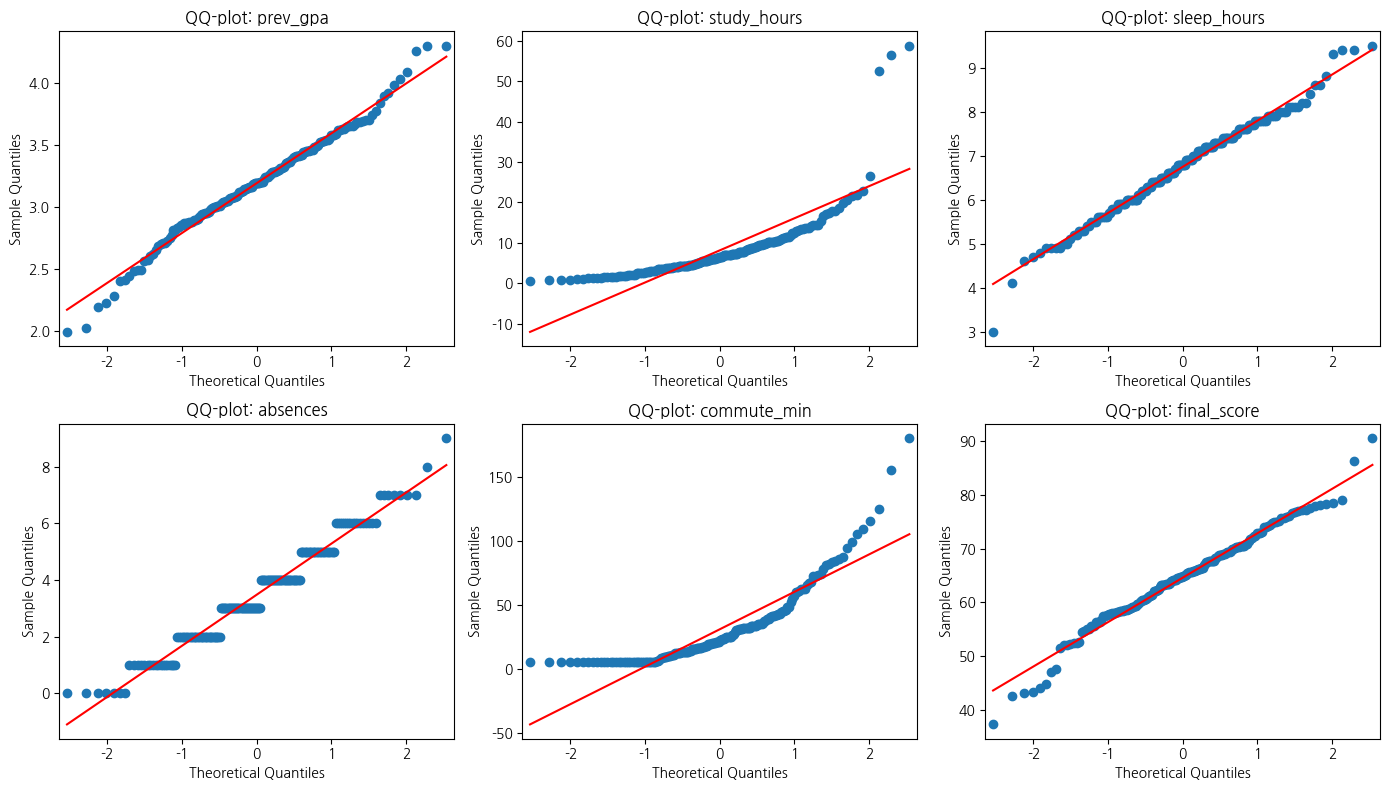

In [16]:
# 3-2) QQ-plot
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.flat, num_cols):
    sm.qqplot(df_clean[c], line='s', ax=ax)
    ax.set_title(f'QQ-plot: {c}')
plt.tight_layout()
plt.show()

In [34]:
# 3-3) 위배 변수에 로그 변환
df_clean['log_study_hours'] = np.log1p(df_clean['study_hours'])
df_clean['log_commute_min'] = np.log1p(df_clean['commute_min'])

print('=== 변환 전/후 비교 ===')
print(f'{"변수":25s} {"왜도":>10s} {"Shapiro p":>12s}')
print('-' * 55)
for c in ['study_hours', 'log_study_hours', 'commute_min', 'log_commute_min']:
    skew = df_clean[c].skew()
    sw_p = stats.shapiro(df_clean[c]).pvalue
    print(f'{c:25s} {skew:+10.3f} {sw_p:12.4f}')

=== 변환 전/후 비교 ===
변수                                왜도    Shapiro p
-------------------------------------------------------
study_hours                   +3.872       0.0000
log_study_hours               +0.169       0.0882
commute_min                   +2.008       0.0000
log_commute_min               +0.033       0.0000


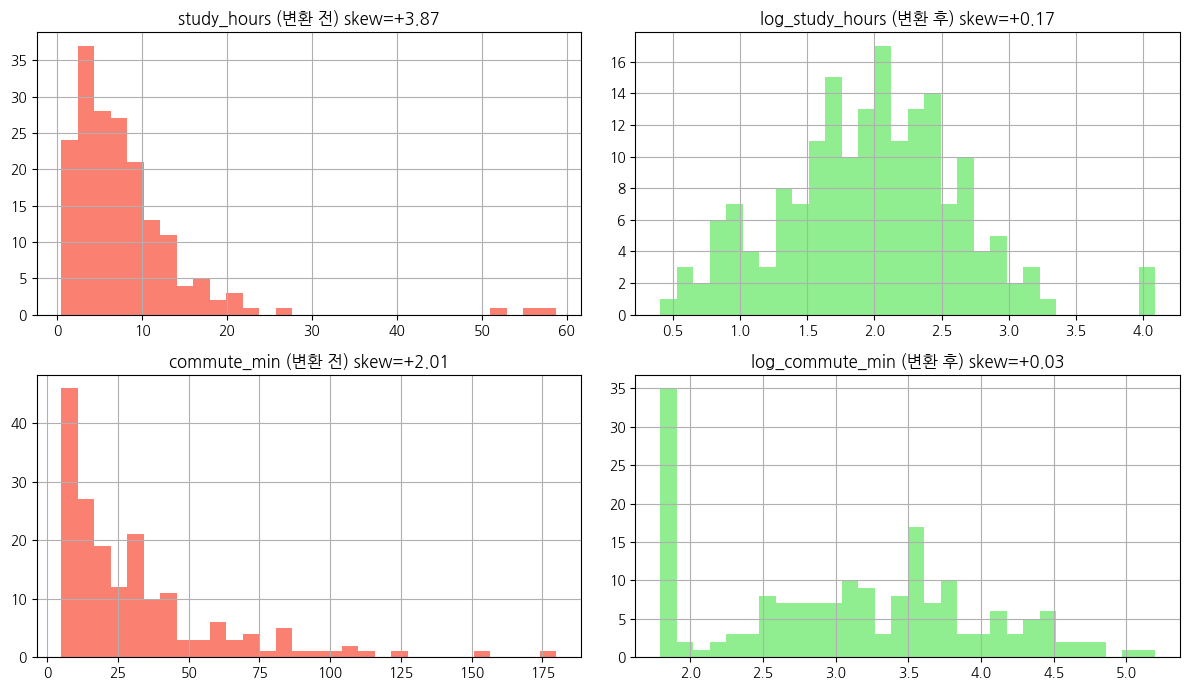

In [33]:
# 3-4) 변환 효과 시각화
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
df_clean['study_hours'].hist(bins=30, ax=axes[0,0], color='salmon')
axes[0,0].set_title(f'study_hours (변환 전) skew={df_clean["study_hours"].skew():+.2f}')
df_clean['log_study_hours'].hist(bins=30, ax=axes[0,1], color='lightgreen')
axes[0,1].set_title(f'log_study_hours (변환 후) skew={df_clean["log_study_hours"].skew():+.2f}')
df_clean['commute_min'].hist(bins=30, ax=axes[1,0], color='salmon')
axes[1,0].set_title(f'commute_min (변환 전) skew={df_clean["commute_min"].skew():+.2f}')
df_clean['log_commute_min'].hist(bins=30, ax=axes[1,1], color='lightgreen')
axes[1,1].set_title(f'log_commute_min (변환 후) skew={df_clean["log_commute_min"].skew():+.2f}')
plt.tight_layout()
plt.show()

### ✓ STEP 3 결과 해석

**정규성 위배** (변환 전, p < 0.05)
- `study_hours`: p < 0.001, skew **+3.87** (강한 우편향)
- `commute_min`: p < 0.001, skew +2.01
- `absences`: p ≈ 0.0002

**정규성 만족** (변환 불필요)
- `prev_gpa`: p = 0.131
- `sleep_hours`: p = 0.236

**Y변수 `final_score`**: p = 0.040 (경계선). 회귀에서 중요한 건 **잔차의 정규성**(STEP 7) → Y 자체는 변환 안 함.

**로그 변환 효과**
- `study_hours` → `log_study_hours`: skew +3.87 → **+0.17**, Shapiro p → **0.088 (정규성 회복!)**
- `commute_min` → `log_commute_min`: skew +2.01 → +0.03 (왜도는 개선), Shapiro p는 여전히 작음

> 💡 모든 변수를 완벽히 정규화하기 어려움. 왜도 완화만으로도 회귀에서 의미 있음.

---
## STEP 4. 가설검정 — 그룹간 final_score 차이 탐색

### 해야 할 일
1. **독립표본 t**: study_group → final_score
2. **ANOVA + Tukey**: scholarship → final_score
3. **카이제곱**: scholarship × study_group 독립성

### 4-1) 독립표본 t-검정

**가설**: H₀: μ(yes) = μ(no) / H₁: μ(yes) ≠ μ(no)
**절차**: Levene → equal_var 결정 → ttest_ind

In [32]:
g_yes = df_clean[df_clean['study_group']=='yes']['final_score']
g_no  = df_clean[df_clean['study_group']=='no']['final_score']

print(f'study_group=yes: n={len(g_yes)}, 평균={g_yes.mean():.2f}, std={g_yes.std():.2f}')
print(f'study_group=no : n={len(g_no)},  평균={g_no.mean():.2f}, std={g_no.std():.2f}')

lev = stats.levene(g_yes, g_no)
print(f'\nLevene p = {lev.pvalue:.4f}  → equal_var = {lev.pvalue > 0.05}')

t_res = stats.ttest_ind(g_yes, g_no, equal_var=(lev.pvalue > 0.05))
print(f't = {t_res.statistic:.4f}, p = {t_res.pvalue:.4f}')

study_group=yes: n=100, 평균=66.08, std=7.74
study_group=no : n=80,  평균=62.79, std=8.63

Levene p = 0.4720  → equal_var = True
t = 2.6938, p = 0.0077


### 4-2) ANOVA + Tukey HSD

**가설**: H₀: μ(none) = μ(partial) = μ(full) / H₁: 적어도 한 쌍은 다르다

In [30]:
groups = [df_clean[df_clean['scholarship']==s]['final_score']
          for s in ['none', 'partial', 'full']]
labels = ['none', 'partial', 'full']

for label, g in zip(labels, groups):
    print(f'{label:10s}: n={len(g)}, 평균={g.mean():.2f}')

f_res = stats.f_oneway(*groups)
print(f'\nANOVA: F = {f_res.statistic:.3f}, p = {f_res.pvalue:.4f}')

tukey = pairwise_tukeyhsd(df_clean['final_score'],
                          df_clean['scholarship'], alpha=0.05)
print('\nTukey HSD 사후검정:')
print(tukey)

none      : n=97, 평균=62.18
partial   : n=55, 평균=67.73
full      : n=28, 평균=66.95

ANOVA: F = 10.094, p = 0.0001

Tukey HSD 사후검정:
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1  group2 meandiff p-adj   lower   upper  reject
-----------------------------------------------------
  full    none  -4.7665  0.015 -8.7706 -0.7624   True
  full partial   0.7773 0.9057 -3.5558  5.1103  False
  none partial   5.5438 0.0001  2.3933  8.6942   True
-----------------------------------------------------


### 4-3) 카이제곱 — scholarship × study_group 독립성

**가설**: H₀: 두 변수는 독립 / H₁: 관련 있음

In [ ]:
ct = pd.crosstab(df_clean['scholarship'], df_clean['study_group'])
print('관측 빈도표:')
print(ct)

chi_res = stats.chi2_contingency(ct)
print(f'\nχ² = {chi_res.statistic:.4f}')
print(f'dof = {chi_res.dof}')
print(f'p = {chi_res.pvalue:.4f}')

print('\n기대 빈도:')
print(pd.DataFrame(chi_res.expected_freq.round(2),
                   index=ct.index, columns=ct.columns))

### ✓ STEP 4 결과 해석

| 검정 | 통계량 | p-value | 결론 |
|---|---|---|---|
| 독립표본 t (study_group) | t = 2.69 | **0.008** | ✓ 스터디 참여 그룹 3.3점 높음 |
| ANOVA (scholarship) | F = 10.09 | **0.0001** | ✓ 매우 유의 |
| Tukey HSD | — | — | none↔partial, none↔full만 유의 |
| 카이제곱 (scholarship × study) | χ² = 3.87 | 0.144 | ✗ 독립 |

**핵심 발견**
1. 스터디 그룹이 final_score를 약 3점 끌어올림
2. 장학금 효과 있음 — 단, **partial vs full 사이 차이 없음** (Tukey)
3. 장학금과 스터디 참여는 **서로 독립**

> 💡 'partial vs full 차이 없음'은 흥미로움 — 장학금 액수보다 '있고 없고'가 중요.

---
## STEP 5. 단순 회귀분석 — prev_gpa → final_score

In [26]:
m1 = smf.ols('final_score ~ prev_gpa', data=df_clean).fit()
print(m1.summary())

                            OLS Regression Results                            
Dep. Variable:            final_score   R-squared:                       0.295
Model:                            OLS   Adj. R-squared:                  0.291
Method:                 Least Squares   F-statistic:                     74.54
Date:                Mon, 08 Jun 2026   Prob (F-statistic):           3.27e-15
Time:                        02:11:22   Log-Likelihood:                -604.09
No. Observations:                 180   AIC:                             1212.
Df Residuals:                     178   BIC:                             1219.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     28.9694      4.162      6.961      0.0

### ✓ STEP 5 결과 해석

**회귀식**: `final_score = 28.97 + 11.17 × prev_gpa`

| 지표 | 값 | 의미 |
|---|---|---|
| β₀ (절편) | 28.97 (p < 0.001) | prev_gpa=0일 때 (실질적 의미 없음) |
| β₁ (기울기) | **11.17** (p < 0.001) | GPA 1점 ↑ → 점수 **11.17점 ↑** |
| R² | **0.295** | 분산의 약 30% 설명 |
| F p-value | 3.27e-15 | 모델 매우 유의 |

**해석**: prev_gpa 단독으로 final_score 분산의 30% 설명. **70%는 다른 요인** → STEP 6 다중회귀로 확장.

> 💡 R² 0.30 = "예측 정확도 30%"가 아님. "Y 변동 중 30%를 X가 설명"한다는 뜻.

---
## STEP 6. 다중 회귀분석 — 전체 변수

In [25]:
formula = ('final_score ~ prev_gpa + log_study_hours + sleep_hours '
           '+ absences + log_commute_min '
           '+ C(study_group) + C(scholarship) + C(part_time_job) '
           '+ C(major) + C(gender)')

m2 = smf.ols(formula, data=df_clean).fit()
print(m2.summary())

                            OLS Regression Results                            
Dep. Variable:            final_score   R-squared:                       0.556
Model:                            OLS   Adj. R-squared:                  0.521
Method:                 Least Squares   F-statistic:                     15.99
Date:                Mon, 08 Jun 2026   Prob (F-statistic):           3.44e-23
Time:                        02:11:20   Log-Likelihood:                -562.49
No. Observations:                 180   AIC:                             1153.
Df Residuals:                     166   BIC:                             1198.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept             

In [28]:
print(f'단순 회귀  : R² = {m1.rsquared:.4f}')
print(f'다중 회귀  : R² = {m2.rsquared:.4f},  Adj.R² = {m2.rsquared_adj:.4f}')
print(f'개선폭     : ΔR² = {m2.rsquared - m1.rsquared:+.4f}')
print(f'\n다중회귀 F = {m2.fvalue:.3f}, p = {m2.f_pvalue:.4g}')

단순 회귀  : R² = 0.2952
다중 회귀  : R² = 0.5561,  Adj.R² = 0.5213
개선폭     : ΔR² = +0.2609

다중회귀 F = 15.994, p = 3.44e-23


### ✓ STEP 6 결과 해석

**모델 성능**
| 모델 | R² | Adj.R² |
|---|---|---|
| 단순 (prev_gpa) | 0.295 | — |
| 다중 (전체) | **0.556** | 0.521 |

→ 다중회귀로 R²가 거의 2배! 변수 추가가 의미 있음.

**유의한 변수 (p < 0.05)**

| 변수 | coef | p-value | 해석 |
|---|---|---|---|
| **prev_gpa** | **+11.81** | 7.6e-21 | 압도적 1위 |
| **absences** | **−1.40** | 8.4e-08 | 결석 1회당 −1.4점 |
| C(scholarship)[T.none] | −4.38 | 0.001 | full 대비 −4.4점 |
| C(study_group)[T.yes] | +2.99 | 0.001 | 스터디 +3점 |
| log_study_hours | +1.92 | 0.005 | 공부시간 효과 |

**가장 영향력 있는 3개**
1. **prev_gpa** (+11.81) — GPA 1점 ↑ = 약 12점 ↑
2. **absences** (−1.40) — 결석 9회 = 약 12점 ↓
3. **scholarship[T.none]** (−4.38) — 장학금 없는 학생이 4점 낮음

**유의하지 않은 변수 — 왜?**
- gender(0.32), major(>0.17), sleep_hours(0.50), part_time_job(0.25), commute(0.68)
- 추측: prev_gpa·absences 같은 강한 변수가 효과를 흡수했을 가능성. '학업 태도와 누적 역량'이 다른 요인을 압도.

> 💡 직관적 결과지만 데이터로 증명 — '과거 학업 성과 + 결석 안 함'이 가장 강한 예측자.

---
## STEP 7. 회귀 진단 — 잔차 분석 LINE

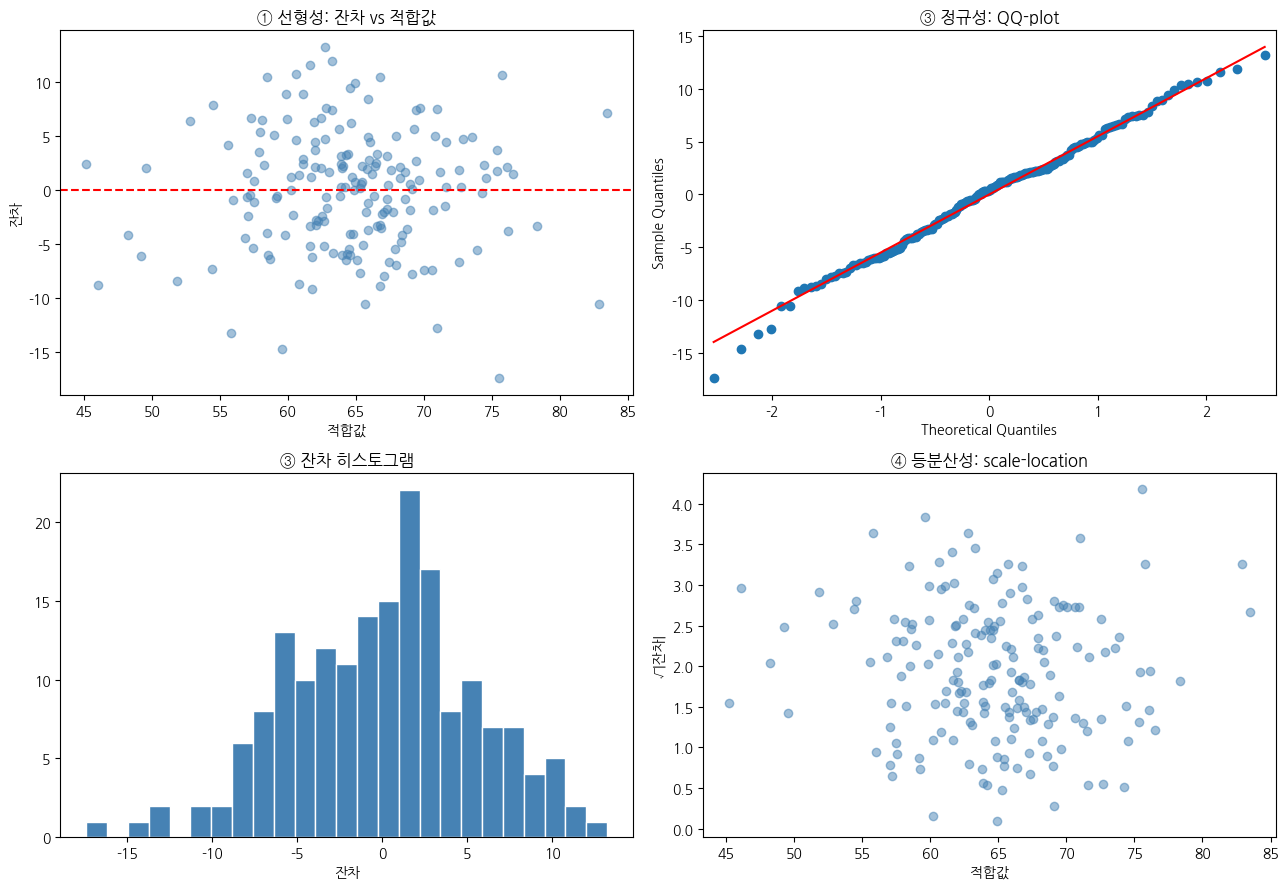

In [21]:
resid = m2.resid
fitted = m2.fittedvalues

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# ① Linearity
axes[0,0].scatter(fitted, resid, alpha=0.5, color='steelblue')
axes[0,0].axhline(0, color='red', linestyle='--')
axes[0,0].set_xlabel('적합값')
axes[0,0].set_ylabel('잔차')
axes[0,0].set_title('① 선형성: 잔차 vs 적합값')

# ③ Normality - QQ
sm.qqplot(resid, line='s', ax=axes[0,1])
axes[0,1].set_title('③ 정규성: QQ-plot')

# ③ Normality - histogram
axes[1,0].hist(resid, bins=25, color='steelblue', edgecolor='white')
axes[1,0].set_xlabel('잔차')
axes[1,0].set_title('③ 잔차 히스토그램')

# ④ Equal variance
axes[1,1].scatter(fitted, np.sqrt(np.abs(resid)), alpha=0.5, color='steelblue')
axes[1,1].set_xlabel('적합값')
axes[1,1].set_ylabel('√|잔차|')
axes[1,1].set_title('④ 등분산성: scale-location')

plt.tight_layout()
plt.show()

In [22]:
print('=' * 60)
print('회귀 진단 — LINE 4가지 가정')
print('=' * 60)

print(f'\n① 선형성 — 잔차 평균 = {resid.mean():.4f} (0에 가까워야 OK)')

dw = durbin_watson(resid)
dw_ok = 1.5 <= dw <= 2.5
print(f'\n② 독립성 — Durbin-Watson = {dw:.3f} ({"OK" if dw_ok else "의심"})')

sw = stats.shapiro(resid)
sw_ok = sw.pvalue > 0.05
print(f'\n③ 정규성 — Shapiro p = {sw.pvalue:.4f} ({"OK" if sw_ok else "위배"})')

bp = het_breuschpagan(resid, m2.model.exog)
bp_ok = bp[1] > 0.05
print(f'\n④ 등분산성 — Breusch-Pagan p = {bp[1]:.4f} ({"OK" if bp_ok else "이분산 의심"})')

print('\n' + '=' * 60)
all_ok = dw_ok and sw_ok and bp_ok
print('종합:', '4가지 가정 모두 만족 — 회귀 결과 신뢰 가능' if all_ok else '일부 가정 위배')
print('=' * 60)

회귀 진단 — LINE 4가지 가정

① 선형성 — 잔차 평균 = 0.0000 (0에 가까워야 OK)

② 독립성 — Durbin-Watson = 1.947 (OK)

③ 정규성 — Shapiro p = 0.6445 (OK)

④ 등분산성 — Breusch-Pagan p = 0.8711 (OK)

종합: 4가지 가정 모두 만족 — 회귀 결과 신뢰 가능


### ✓ STEP 7 결과 해석

| 가정 | 검정 | 값 | 판정 |
|---|---|---|---|
| ① 선형성 | 잔차-적합값 산점도 | 무작위 | ✓ OK |
| ② 독립성 | Durbin-Watson | **1.947** | ✓ OK |
| ③ 정규성 | Shapiro on resid | **p = 0.645** | ✓ OK |
| ④ 등분산성 | Breusch-Pagan | **p = 0.871** | ✓ OK |

**🎉 종합 — 4가지 가정 모두 만족 → 회귀 결과 신뢰 가능**

**의미**: 잔차가 정규분포에 가깝고(p=0.645), 분산이 일정(p=0.871), 자기상관 없음(DW=1.95), 잔차에 패턴 없음 → t-검정·CI 정확함.

> 💡 현실에서 4가지 가정 모두 만족은 드뭄. 일부 위배 시 정직히 기록 + Robust SE 등 대안 고려.

###다중공선성 점검 (VIF)
VIF > 10이면 회귀계수가 불안정해질 수 있음.

In [23]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_check = df_clean[['prev_gpa', 'log_study_hours', 'sleep_hours',
                    'absences', 'log_commute_min']].copy()
X_check = sm.add_constant(X_check)

vif = pd.DataFrame()
vif['variable'] = X_check.columns
vif['VIF'] = [variance_inflation_factor(X_check.values, i)
              for i in range(X_check.shape[1])]
print('VIF (10 미만이면 OK):')
print(vif.round(3))

VIF (10 미만이면 OK):
          variable      VIF
0            const  132.250
1         prev_gpa    1.010
2  log_study_hours    1.056
3      sleep_hours    1.014
4         absences    1.015
5  log_commute_min    1.055


**VIF 결과**: 모든 수치 변수의 VIF가 1~2로 낮음 → 다중공선성 문제 없음.